# Heat Conduction 

**Method**: Separation of Variables \
**Boundary Conditions**: Non-Homogenous

This notebook solves the problem depicted in Slide 27 of Topic 10.

In [29]:
# Imports
import numpy as np
import matplotlib.pyplot as plt

## Input Variables for the program

***Refer to the following information about variables if you are stuck!***

|Variable| Description |
|:-----|:--|
|`nstep`| Number of time steps |
|`tmax` | Maximum time |
|`dt` | Time step|
|`t` | Time Array |
|`Nt`| Number of evaluation points in time |
|`N_sum`| Number of summation components in the final expression |
|`L`| Length of block|
|`dx`| Step size in space |
|`xx`| Array of Evaluation points along the length|
|`Nx`| Number of evaluation points along the length|
|`T_tr`| Array of different components of Temperature (Transient Contribution) at evaluation points|
|`T_ss`| Array of Temperature (Steady State Contribution) at evaluation points|
|`T_tr_tot`| Array of Temperature at evaluation points|
|`alpha`| Heat Diffusivity|
|`T0`| Initial Temperature |
|`T1`| Temperature at Left BC |
|`T2`| Temperature at Right BC |

## Additional Information about variables
<pre>
<code> xx </code>:     Contains the list of evaluation points from 0 to L with a step size of dx.
          Shape: (L/dx + 1, 1)
          xx[n]: Location at x = n*dx

<code> T_tr </code>:     Contains the array of transeint contribution of different components of sum at different locations and time.
          Shape: (No. of sum components, No. of eval. pts. in space, No. of eval. pts in time)
          T_tr[m, n, p] ==> mth Transient temperature component at n*L/10, at time p*dt

<code> T_tr_tot </code>:   Contains the array of Temperature measurements at different locations and time.
          Shape: (No. of eval. pts. in space, No. of eval. pts in time)
          T_tot[1, n, p] ==> Temperature at n*L/10, at time p*dt

<code> T_ss </code>:   Contains the array of Steady State contribution of Temperature measurements at different locations.
          Shape: (No. of eval. pts. in space, No. of eval. pts in time)
          T_ss[n] ==> SS Temperature contribution at n*L/10
</pre>    


## System Inputs

In [30]:
nstep   =  5                                # Higher value of nstep improves the solution, but will take more time to run!
tmax    =  10000                            # Indicative upper limit; determine on basis of expected lenght of the process (note that its tail should have decayed completely) 
dt      = tmax/nstep
t       = np.arange(0, tmax+dt, dt)         # Time vector (evaluation points in time)
Nt      = len(t) 
N_sum   =  5                                # number of components to include in the sum (final solution derived in Slide 21)


# Geometry
L       = 0.5                               # Length
dx      = L/10
xx      = np.arange(0, L+dx, dx)            # Space Vector (evaluation points along the length)
Nx      = len(xx)

print("Time Steps: \t\t\t", nstep)
print("Spatial Steps: \t\t\t",  Nx)
print("Number of Sum components: \t", N_sum)

Time Steps: 			 5
Spatial Steps: 			 11
Number of Sum components: 	 5


In [31]:
#--------------------------------------------------------------------------
#Inhomogenous BCs
#note this only works for constant initial conditions

# Parameter values 
alpha   = 1e-5
T1      = 0
T2      = 20
T0      = 5
#--------------------------------------------------------------------------

T_ss       = np.zeros(Nx)
T_tr       = np.zeros((N_sum, Nx, Nt))
T_tr_tot   = np.zeros((1, Nx, Nt))

T_ss       = T1+(T2-T1)/L*xx

Const1 = 2*(T2-T1) - 4*(T0-T1)
Const2 = 2*(T2-T1)

#Const1=40
#Const2=10

## Computation of Temperature (as derived in slides)

Recall that the derived solution for temperature reads:

\begin{aligned}
    T(x, t) = T_{ss} - \sum_{n = 1, n = \text{odd}}^{\infty}\frac{C_1}{n\pi} e^{-\frac{\alpha n^2 \pi^2 t}{L^2}} \sin{\left( \frac{n\pi x}{L} \right)} + \sum_{n = 1, n = \text{even}}^{\infty}\frac{C_2}{n\pi} e^{-\frac{\alpha n^2 \pi^2 t}{L^2}} \sin{\left( \frac{n\pi x}{L} \right)}
\end{aligned}

This has been computed in the next code block

In [32]:
# kk refers to the component number index (corresponds to n in the above formula)
# tt refers to the timestep index (t[tt] corresponds to t in the above formula)

for kk in np.arange(1,2*N_sum,2):
    for jj in np.arange(0, Nt, 1):
        T_tr[kk//2,:,jj] = - Const1/(kk*np.pi)*np.exp(-alpha*kk**2*np.pi**2*t[jj]/L**2)*np.sin(kk*np.pi*xx/L) +  Const2/((kk+1)*np.pi)*np.exp(-alpha*(kk+1)**2*np.pi**2*t[jj]/L**2)*np.sin((kk+1)*np.pi*xx/L);
        
#T_tr_tot = sum(T_tr)
T_tr_tot  = np.sum(T_tr, axis=0)+ T_ss[:,np.newaxis]

### Evaluate the value of `T_tot` at given location and time.

In [33]:
# Check the value of T_tot at
x_eval = L/2                    
t_eval = tmax/nstep * 3


# Display the value of T_tot at evaluation point
ix = round((Nx-1)/L * x_eval)
it = round((Nt-1)/tmax * t_eval)
print(f"Value at x = {xx[ix]} m, t = {t[it]}s")
print(f"{T_tr_tot[ix, it]:.3f}")

Value at x = 0.25 m, t = 6000.0s
9.404


## Visualize the results

### 1. Temperature Distribution in space for different time moments

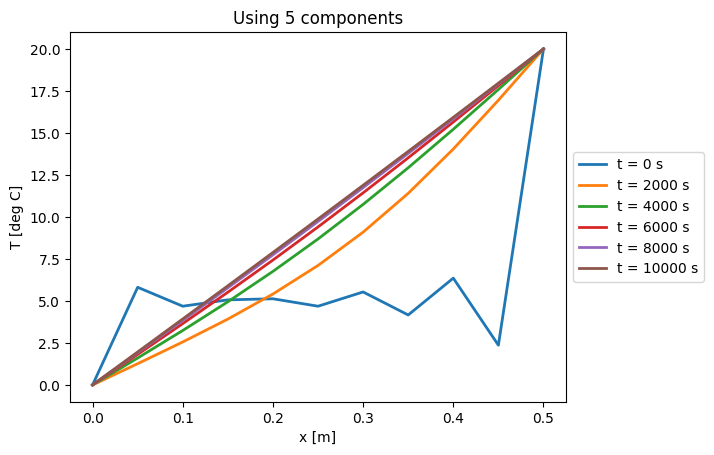

In [34]:
# Initialize Figure
plt.figure()

# Number of plots/interested points of time
Np = 5                                  
t_index = np.arange(0, Nt, Nt//Np) 


# Plot the state at different points of time
for pp in range(len(t_index)):
    plt.plot(xx, T_tr_tot[:,t_index[pp]], linewidth=2, label = f't = {t[t_index[pp]]:.0f} s')


# Add Title, Labels and Legends
#plt.title(f"Temperature States at Different Moments of Time when n = {N_sum}")
plt.title(f"Using {N_sum} components")
plt.xlabel('x [m]')
plt.ylabel('T [deg C]')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5));

### 2. Visualization of Steady State of Temperature Distribution

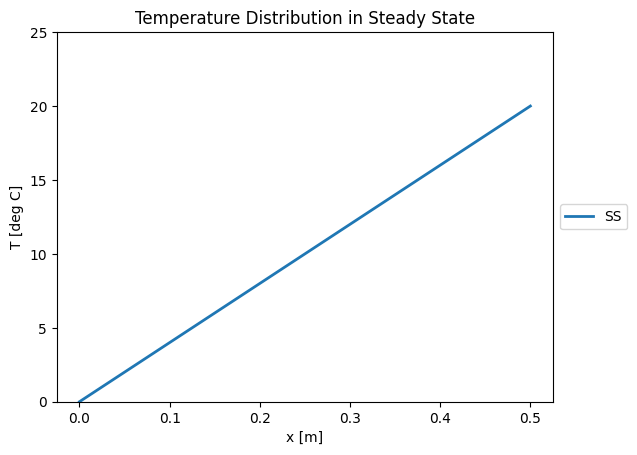

In [35]:
plt.figure()

plt.plot(xx, T_ss, linewidth = 2, label = 'SS')
plt.xlabel('x [m]')
plt.ylabel('T [deg C]')
plt.ylim(0,25)
plt.title("Temperature Distribution in Steady State")
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5));


### 3. Different components of Temperature solution at different time moments 

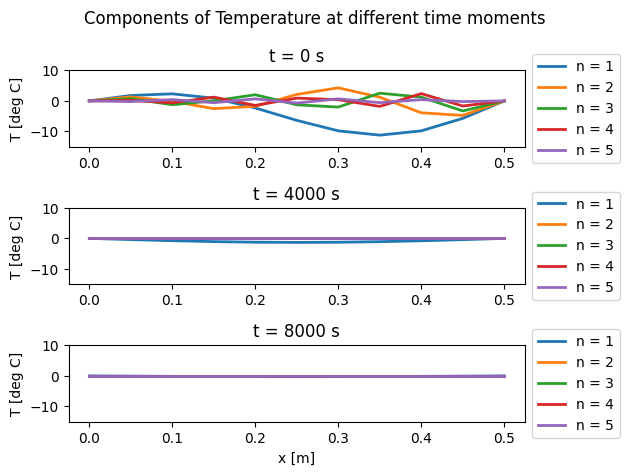

In [36]:
# Initialize Figure
plt.figure()

# Number of Sub Plots
N_fig = 3

t_index= np.arange(0, Nt, Nt//N_fig)


for subFig in range(1, N_fig+1):
    plt.subplot(N_fig,1,subFig)

    Np = N_sum
    N_sum_index= np.arange(0, N_sum, N_sum//Np)

    for pp in range(len(N_sum_index)):
        plt.plot(xx, T_tr[N_sum_index[pp],:,t_index[subFig-1]], label = f"n = {(N_sum_index[pp]+1)}", linewidth = 2)
        plt.ylim(-15, 10)


    plt.title(f"t = {t[t_index[subFig - 1]]:.0f} s")
    plt.ylabel('T [deg C]')   
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.suptitle('Components of Temperature at different time moments')
plt.xlabel('x [m]')

# Automatically adjust the spacing to avoid overlap between titles and plots
plt.tight_layout();